**本篇对模型可能出现的欠拟合和过拟合的情况进行实验**

In [194]:
import math
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

In [195]:
#模型多项式的最大阶数（超过即将拟合的真实函数，一个三次函数
max_degree = 20 
#分配空间
true_w = np.zeros(max_degree)
#输入真实值
true_w[0:4] = np.array([5, 1.2, -3.4, 5.6])

#训练和测试数据集大小
n_train, n_test = 100, 100 
#获取数据集（测试集 + 训练集）
features = np.random.normal(size=(n_train + n_test, 1))
np.random.shuffle(features) #打乱

#用于生成多项式 [x^0, x^1, ..., x^19]
#这里 poly_features 是 300 * 20 的，前 200 个用作训练，后 100 个用于测试
poly_features = np.power(features, np.arange(max_degree).reshape(1, -1))
#其实类似泰勒展开，除以阶乘，防止多项式结果过大，避免高次项占主导
for i in range(max_degree):
    poly_features[:, i] /= math.gamma(i + 1)  #gamma(n)=(n-1)!

#labels的维度:(n_train+n_test,)
#在每一个项前乘以权重系数 w_i
labels = np.dot(poly_features, true_w)
#加上噪声
labels += np.random.normal(scale=0.2, size=labels.shape)

In [196]:
# NumPy ndarray转换为tensor，使用 torch 框架
true_w, features, poly_features, labels = [torch.tensor(x, dtype=
    torch.float32) for x in [true_w, features, poly_features, labels]]

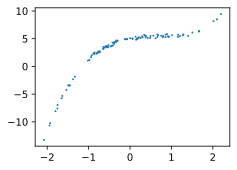

In [197]:
#看一下数据（仅看前 4 个维度的）
#可以看到数据点分布于 y = 5 + 1.2 * x - 3.4 * (x^2 / 2!) + 5.6 * (x^3 / 3!)
d2l.set_figsize()
d2l.plt.scatter(features[:n_train].detach().numpy(), labels[:n_train].detach().numpy(), 1)

In [103]:
#评估损失，输出损失率
def evaluate_loss(net, data_iter, loss):
    #损失的总和,样本数量
    metric = d2l.Accumulator(2)  
    for X, y in data_iter:
        out = net(X)
        y = y.reshape(out.shape)
        l = loss(out, y)
        metric.add(l.sum(), l.numel())
    return metric[0] / metric[1]

In [104]:
#这几行代码是照抄前面的代码实现，因为新版本的代码包把这些删了，所以只能自定义
def evaluate_accuracy(net, data_iter):
    if isinstance(net, nn.Module):net.eval()
    metric = d2l.Accumulator(2)
    with torch.no_grad():
        for X, y in data_iter:metric.add(d2l.accuracy(net(X), y), y.numel())
    if isinstance(net, nn.Module):net.train()
    return metric[0] / metric[1]
def train_epoch_ch3(net, train_iter, loss, updater):
    if isinstance(net, nn.Module):net.train()
    metric = d2l.Accumulator(3)
    for X, y in train_iter:
        y_hat = net(X)
        l = loss(y_hat, y)
        if isinstance(updater, torch.optim.Optimizer):
            updater.zero_grad()
            l.mean().backward()
            updater.step()
        else:
            l.sum().backward()
            updater(X.shape[0])
        metric.add(float(l.sum()), d2l.accuracy(net(X), y), y.numel())
    return metric[0]/metric[2], metric[1]/metric[2]

In [105]:
#训练函数
def train(train_features, test_features, train_labels, test_labels, num_epochs=400):
    loss = nn.MSELoss(reduction='none')
    input_shape = train_features.shape[-1]
    #不设置偏置，因为我们已经在多项式中实现了它，即 x^0 项
    #单层神经网络
    net = nn.Sequential(nn.Linear(input_shape, 1, bias=False))
    batch_size = min(10, train_labels.shape[0])
    train_iter = d2l.load_array((train_features, train_labels.reshape(-1,1)),
                                batch_size)
    test_iter = d2l.load_array((test_features, test_labels.reshape(-1,1)),
                               batch_size, is_train=False)
    trainer = torch.optim.SGD(net.parameters(), lr=0.01)
    animator = d2l.Animator(xlabel='epoch', ylabel='loss', yscale='log',
                            xlim=[1, num_epochs], ylim=[1e-3, 1e2],
                            legend=['train', 'test'])
    for epoch in range(num_epochs):
        train_epoch_ch3(net, train_iter, loss, trainer)
        if epoch == 0 or (epoch + 1) % 20 == 0:
            animator.add(epoch + 1, (evaluate_loss(net, train_iter, loss),
                                     evaluate_loss(net, test_iter, loss)))
    print('weight:', net[0].weight.data.numpy())

### 正常拟合

weight: [[ 5.030556   1.2785393 -3.425113   5.3846383]]


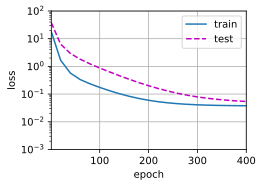

In [ ]:
#从多项式特征中选择前4个维度，即 1, x, x^2/2!, x^3/3! 对数据进行拟合 
#这与真实数据的维度相同，因此拟合效果最好（泛化误差小）
train(poly_features[:n_train, :4], poly_features[n_train:, :4], 
      labels[:n_train], labels[n_train:])

### 欠拟合

weight: [[3.451881  3.5473776]]


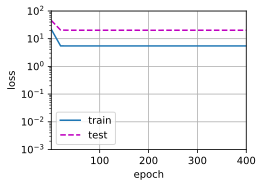

In [201]:
#从多项式特征中选择前2个维度，即 1, x 对数据进行拟合 
#这比真实数据的维度低，学习效果弱，可以看到泛化误差和训练误差一直居高不下
train(poly_features[:n_train, :2], poly_features[n_train:, :2], 
      labels[:n_train], labels[n_train:])

### 过拟合

weight: [[ 4.988785    1.300669   -3.185955    5.1320667  -0.8027783   1.3333608
   0.1201826  -0.09333836 -0.07663685  0.14810164 -0.03861726 -0.06450623
  -0.18108205  0.03081885 -0.11269203 -0.14424698 -0.162215    0.02392779
   0.09783408 -0.09456405]]


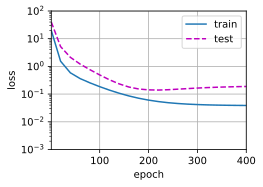

In [ ]:
#从多项式特征中选择 20 个维度，即 1, x ~ x^19 对数据进行拟合 
#这比真实数据的维度高，学习效果太强，可以看到泛化误差先减小后增大
train(poly_features[:n_train, :20], poly_features[n_train:, :20], 
      labels[:n_train], labels[n_train:])